In [148]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from sklearn.model_selection import train_test_split
from sklearn.linear_model import LinearRegression
from sklearn.metrics import mean_absolute_error, mean_squared_error, r2_score

from sklearn.linear_model import RidgeCV, LassoCV
from sklearn.preprocessing import StandardScaler
from sklearn.pipeline import make_pipeline

In [149]:
dataset = pd.read_csv(r"C:\Users\VarunKarmikanda\msis\sem1\aml\aml\data\income_data.csv")
dataset.head()

,Unnamed: 0,income,happiness
0,1,3.862647,2.314489
1,2,4.979381,3.433490
2,3,4.923957,4.599373
3,4,3.214372,2.791114
4,5,7.196409,5.596398


In [150]:
dataset.columns

Index(['Unnamed: 0', 'income', 'happiness'], dtype='object')

In [151]:
data = dataset.drop(columns="Unnamed: 0", axis=1)
data.head()

,income,happiness
0,3.862647,2.314489
1,4.979381,3.433490
2,4.923957,4.599373
3,3.214372,2.791114
4,7.196409,5.596398


In [152]:
X = data[["income"]]
y = data[["happiness"]]

In [153]:
X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.2, random_state=42)

In [154]:
model = LinearRegression()
model.fit(X_train, y_train)

LinearRegression()

In [155]:
y_pred = model.predict(X_test)

In [156]:
print("Intercept: ", model.intercept_)
print("coef: ", model.coef_[0])

print("mean_absolute_error: ", mean_absolute_error(y_test, y_pred))
print("mean_squared_error: ", mean_squared_error(y_test, y_pred))
print("root_mean_squared_error: ", np.sqrt(mean_squared_error(y_test, y_pred)))
print("r2_score: ", r2_score(y_test, y_pred))

Intercept:  [0.14170387]
coef:  [0.7247687]
mean_absolute_error:  0.6269683431894553
mean_squared_error:  0.590146394343082
root_mean_squared_error:  0.768209863476825
r2_score:  0.6662585264303965


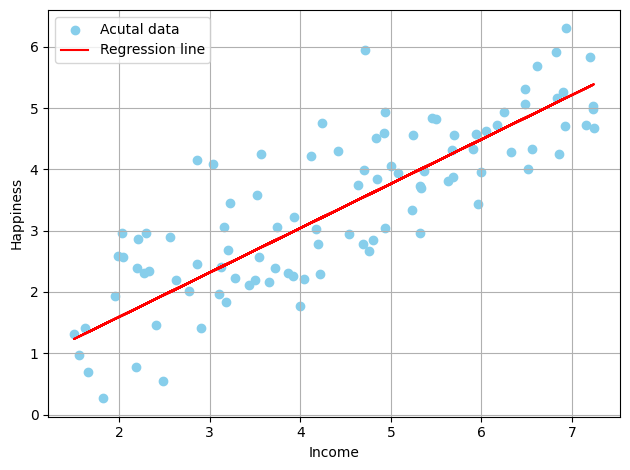

In [157]:
plt.scatter(X_test, y_test, c="skyblue", label="Acutal data")
plt.plot(X_test, y_pred, c="red", label="Regression line")

plt.legend()
plt.xlabel("Income")
plt.ylabel("Happiness")

plt.tight_layout()
plt.grid()
plt.show()

# RIDGE

In [158]:
ridge_model = make_pipeline(
    StandardScaler(),
    RidgeCV(alphas=[0.01, 0.1, 1, 10, 100])
)

ridge_model.fit(X_train, y_train)

Pipeline(steps=[('standardscaler', StandardScaler()),
                ('ridgecv', RidgeCV(alphas=[0.01, 0.1, 1, 10, 100]))])

In [159]:
ridge = ridge_model.named_steps["ridgecv"]
print("Best alpha: ", ridge.alpha_)

Best alpha:  0.1


In [160]:
y_pred = ridge_model.predict(X_test)

In [161]:
print("Intercept: ", ridge.intercept_)
print("coef: ", ridge.coef_[0])

print("mean_absolute_error: ", mean_absolute_error(y_test, y_pred))
print("mean_squared_error: ", mean_squared_error(y_test, y_pred))
print("root_mean_squared_error: ", np.sqrt(mean_squared_error(y_test, y_pred)))
print("r2_score: ", r2_score(y_test, y_pred))

Intercept:  [3.3881444]
coef:  1.2741061319246618
mean_absolute_error:  0.6269402572905592
mean_squared_error:  0.5900863905372834
root_mean_squared_error:  0.7681708081782875
r2_score:  0.6662924599742748


# LASSO

In [162]:
lasso_model = make_pipeline(
    StandardScaler(),
    LassoCV(alphas=[0.01, 0.1, 1, 10, 100])
)
lasso_model.fit(X_train, y_train)

C:\Users\VarunKarmikanda\AppData\Roaming\Python\Python313\site-packages\sklearn\linear_model\_coordinate_descent.py:1664: DataConversionWarning: A column-vector y was passed when a 1d array was expected. Please change the shape of y to (n_samples, ), for example using ravel().
  y = column_or_1d(y, warn=True)


Pipeline(steps=[('standardscaler', StandardScaler()),
                ('lassocv', LassoCV(alphas=[0.01, 0.1, 1, 10, 100]))])

In [163]:
lasso = lasso_model.named_steps["lassocv"]
print("Best alpha: ", lasso.alpha_)

Best alpha:  0.01


In [164]:
y_pred = lasso_model.predict(X_test)

In [165]:
print("Intercept: ", lasso.intercept_)
print("Coef: ", lasso.coef_[0])

print("MAE: ", mean_absolute_error(y_test, y_pred))
print("MSE: ", mean_squared_error(y_test, y_pred))
print("RMAE: ", np.sqrt(mean_absolute_error(y_test, y_pred)))
print("R2: ", r2_score(y_test, y_pred))

Intercept:  3.3881444001909546
Coef:  1.2644262590942457
MAE:  0.6261314479108001
MSE:  0.5883565265782998
RMAE:  0.7912846819639567
R2:  0.6672707381647037
